In [ ]:
from pathlib import Path
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

project_root = Path.cwd()
if project_root.name == "notebooks":
    project_root = project_root.parent

sys.path.insert(0, str(project_root / "src"))

from tp4.data import load_creators, standardise
from tp4.linear.oja import fit_oja, creator_index
from tp4.linear.pca import fit_pca

data_path = project_root / "data" / "creadores.csv"

original_df = pd.read_csv(data_path)

df = load_creators(str(data_path))
X, scaler = standardise(df)

print(f"Creators: {X.shape[0]}")
print(f"Variables: {X.shape[1]}")

df.head()

Creators: 50
Variables: 28


,followers,average_reach,average_impressions,average_video_views,monthly_posts,argentina_audience_pct,estimated_argentina_reach,non_follower_reach_pct,likes_per_1000,comments_per_1000,...,topic_art_pct,content_tutorial_pct,content_review_pct,content_entertainment_pct,content_showcase_pct,average_caption_words,average_watch_time_seconds,video_posts_pct,short_form_posts_pct,trend_posts_pct
0,775589,245722,369678,176505,26,83.19,204416,55.95,41.61,2.39,...,15.30,2.78,13.73,68.36,15.13,56.19,18.85,58.43,60.03,49.20
1,638718,235620,281643,180650,15,29.78,70168,77.77,47.47,2.20,...,6.93,9.92,10.89,69.30,9.89,54.05,20.76,66.49,70.47,54.14
2,13235,4193,6339,2378,10,94.43,3959,30.10,27.00,4.96,...,15.29,59.48,27.54,0.38,12.60,180.74,31.07,24.95,21.89,13.05
3,333692,98820,155470,78156,15,42.10,41603,80.57,49.50,3.89,...,70.19,24.83,24.01,11.13,40.03,66.94,19.08,66.01,72.68,56.46
4,461892,178805,210636,138941,7,68.30,122124,82.10,50.75,3.36,...,10.44,8.25,2.84,85.91,3.00,50.88,20.94,66.84,66.69,54.03


In [ ]:
pca = fit_pca(X)
pc1 = pca.components_[0]

# Tren Oja
weights, history = fit_oja(
    X,
    learning_rate=0.001,
    epochs=2000,
    seed=42
)

if weights @ pc1 < 0:
    weights = -weights

oja_scores = creator_index(X, weights)
pca_scores = pca.transform(X)[:, 0]

cosine_similarity = weights @ pc1
score_correlation = np.corrcoef(oja_scores, pca_scores)[0, 1]

print(f"Cosine similarity between Oja and PC1: {cosine_similarity:.5f}")
print(f"Correlation between scores: {score_correlation:.5f}")

Cosine similarity between Oja and PC1: 0.99986
Correlation between scores: 0.99999


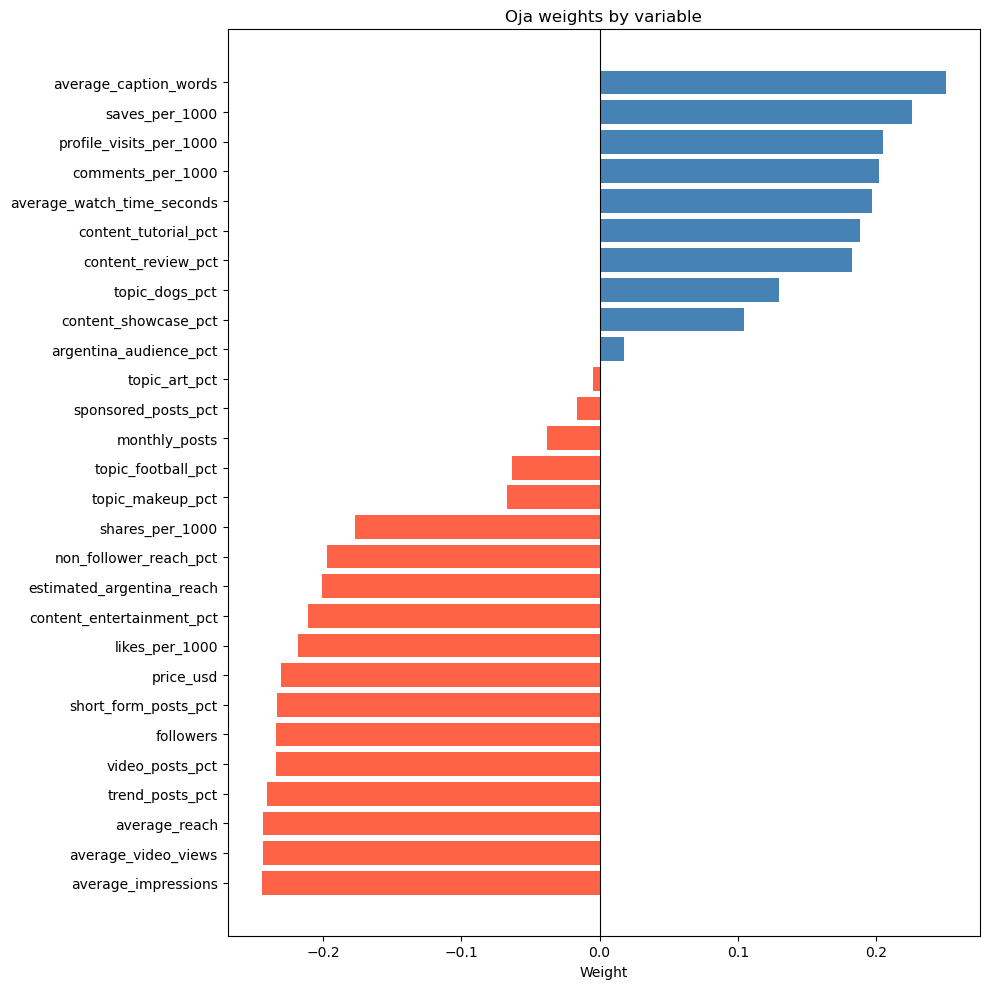

In [4]:
weights_df = pd.DataFrame({
    "Variable": df.columns,
    "Oja weight": weights
}).sort_values("Oja weight")

fig, ax = plt.subplots(figsize=(10, 10))

colors = [
    "tomato" if value < 0 else "steelblue"
    for value in weights_df["Oja weight"]
]

ax.barh(weights_df["Variable"], weights_df["Oja weight"], color=colors)
ax.axvline(0, color="black", linewidth=0.8)
ax.set_title("Oja weights by variable")
ax.set_xlabel("Weight")
ax.set_ylabel("")

plt.tight_layout()
plt.show()

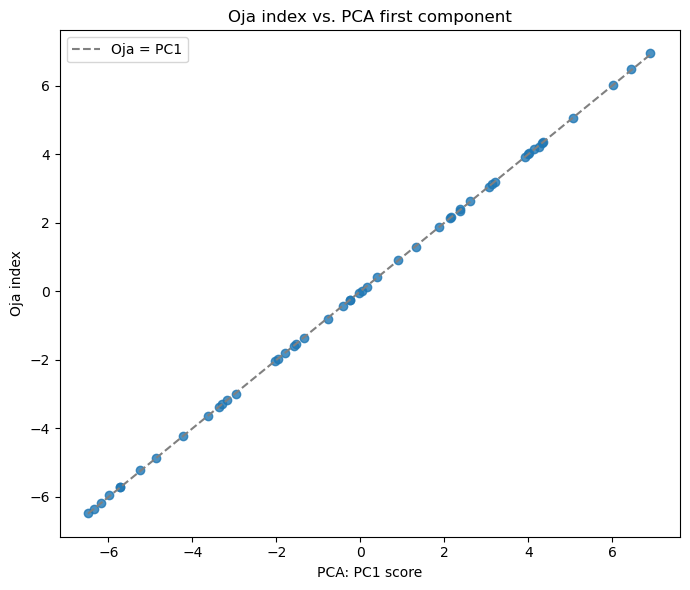

Weight cosine similarity: 0.99986
Score correlation: 0.99999


In [ ]:
fig, ax = plt.subplots(figsize=(7, 6))

ax.scatter(pca_scores, oja_scores, alpha=0.8)

low = min(pca_scores.min(), oja_scores.min())
high = max(pca_scores.max(), oja_scores.max())
ax.plot([low, high], [low, high], "--", color="grey", label="Oja = PC1")

ax.set_title("Oja index vs. PCA first component")
ax.set_xlabel("PCA: PC1 score")
ax.set_ylabel("Oja index")
ax.legend()

plt.tight_layout()
plt.show()

print(f"Weight cosine similarity: {cosine_similarity:.5f}")
print(f"Score correlation: {score_correlation:.5f}")

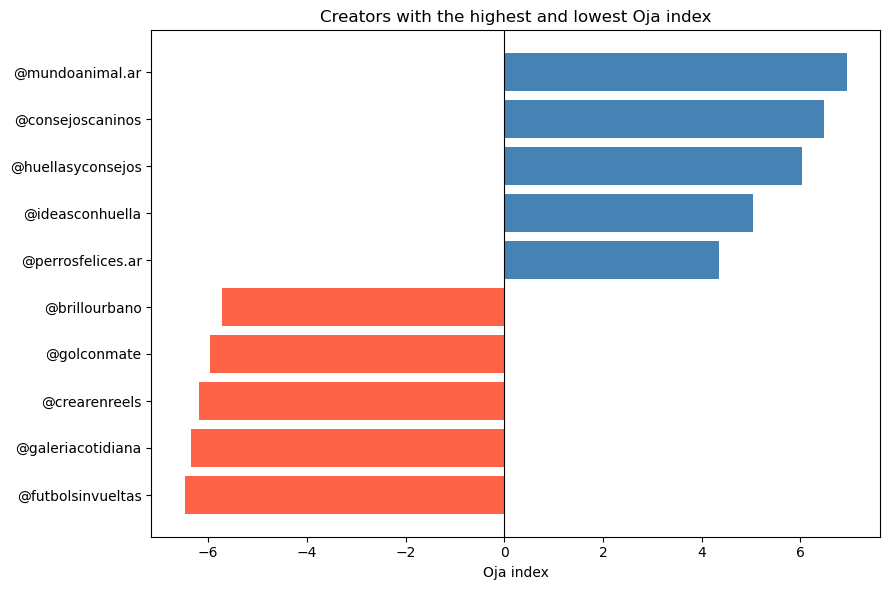

,name,oja_index,pc1
30,@mundoanimal.ar,6.942576,6.899044
42,@consejoscaninos,6.471594,6.442173
2,@huellasyconsejos,6.033415,6.022236
27,@ideasconhuella,5.046551,5.071253
18,@perrosfelices.ar,4.348043,4.346586
26,@pasionalbirroja,4.323239,4.320008
24,@reelargentino,4.218048,4.248018
36,@pasiondepotrero,4.139198,4.127617
22,@clubdelasmascotas,4.036964,4.025067
14,@guiadehuellas,3.994915,3.993395


In [ ]:
results = pd.DataFrame({
    "name": original_df["name"],
    "oja_index": oja_scores,
    "pc1": pca_scores
}).sort_values("oja_index", ascending=False)

extremes = pd.concat([
    results.tail(5),
    results.head(5)
]).sort_values("oja_index")

fig, ax = plt.subplots(figsize=(9, 6))

colors = [
    "tomato" if score < 0 else "steelblue"
    for score in extremes["oja_index"]
]

ax.barh(extremes["name"], extremes["oja_index"], color=colors)
ax.axvline(0, color="black", linewidth=0.8)
ax.set_title("Creators with the highest and lowest Oja index")
ax.set_xlabel("Oja index")
ax.set_ylabel("")

plt.tight_layout()
plt.show()

results.head(10)

In [ ]:
profiles = original_df.copy()
profiles["oja_index"] = oja_scores

top_5 = profiles.nlargest(5, "oja_index")
bottom_5 = profiles.nsmallest(5, "oja_index")

columns_to_compare = [
    "followers",
    "average_reach",
    "price_usd",
    "average_caption_words",
    "saves_per_1000",
    "topic_dogs_pct",
    "topic_football_pct",
    "argentina_audience_pct",
]

comparison = pd.DataFrame({
    "Highest 5: average": top_5[columns_to_compare].mean(),
    "Lowest 5: average": bottom_5[columns_to_compare].mean()
})

comparison.round(2)

,Highest 5: average,Lowest 5: average
followers,21612.20,561962.80
average_reach,4761.20,241345.20
price_usd,175.38,4584.29
average_caption_words,180.01,40.64
saves_per_1000,20.77,7.37
topic_dogs_pct,69.41,21.17
topic_football_pct,8.73,36.76
argentina_audience_pct,73.62,61.41


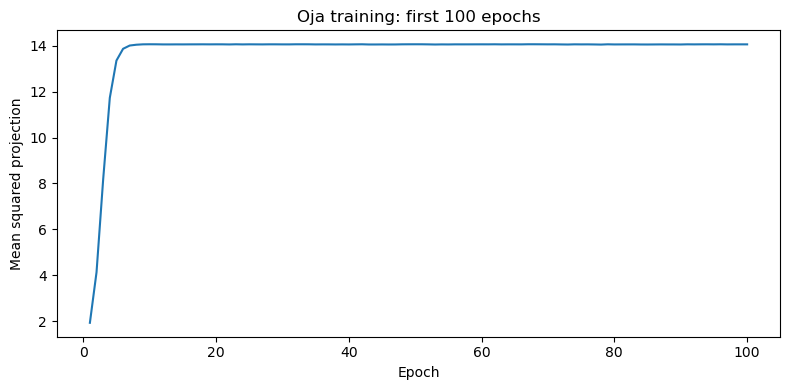

In [8]:
fig, ax = plt.subplots(figsize=(8, 4))

ax.plot(range(1, 101), history[:100])
ax.set_title("Oja training: first 100 epochs")
ax.set_xlabel("Epoch")
ax.set_ylabel("Mean squared projection")

plt.tight_layout()
plt.show()